# Olist | Vendas e Receita
### Análise exploratória do desempenho comercial

**Perguntas do projeto**

1. Como as vendas se distribuem na base e qual é a qualidade dos dados?
2. Como evoluem mensalmente o **número de pedidos**, o **valor dos produtos vendidos** e o **ticket médio**?
3. Quais **categorias**, **estados** e **municípios** respondem pela maior parte das vendas?
4. Quais **produtos vendem mais unidades** e quais **geram maior valor de vendas**?

> **Definição indispensável:** aqui chamamos de **valor de vendas** a soma dos preços dos itens de pedidos entregues, **sem frete**. Trata-se de um indicador comercial semelhante ao GMV dos produtos — **não representa a receita contábil nem o lucro da plataforma Olist**.

**Escopo:** apenas bases originais Olist, quatro CSVs, um notebook e análises descritivas. Sem projeções, dados externos ou modelos preditivos.

## 1. Preparação

Coloque os quatro CSVs necessários em `data/raw/`. O notebook pode ser executado a partir da pasta raiz do projeto ou da pasta `notebooks/`.

**Janela de análise:** janeiro de 2017 até agosto de 2018 (inclusive). O recorte é configurável; foi escolhido para evitar os limites mais incompletos da amostra pública.

In [1]:
from pathlib import Path
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
if not (RAIZ / "data" / "raw").exists():
    raise FileNotFoundError("Abra o notebook dentro da pasta do projeto, que deve conter data/raw/.")

DADOS = RAIZ / "data" / "raw"
SAIDA = RAIZ / "outputs"
GRAFICOS = SAIDA / "graficos"
SAIDA.mkdir(parents=True, exist_ok=True)
GRAFICOS.mkdir(parents=True, exist_ok=True)

INICIO = pd.Timestamp("2017-01-01")
FIM_EXCLUSIVO = pd.Timestamp("2018-09-01")

CORES = {"azul": "#19344D", "turquesa": "#16867A", "dourado": "#DFAE40", "cinza": "#6B7785", "grade": "#DFE5EB"}
plt.rcParams.update({"figure.figsize": (11, 5.2), "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 14,
                     "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

def moeda(v, casas=0):
    return "R$ " + f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def numero(v):
    return f"{int(v):,}".replace(",", ".")

def percentual(v):
    return f"{100 * v:.1f}%".replace(".", ",")

def sem_acentos(texto):
    t = str(texto).strip().upper()
    return "".join(c for c in unicodedata.normalize("NFKD", t) if not unicodedata.combining(c))

def finalizar_grafico(nome):
    plt.tight_layout()
    plt.savefig(GRAFICOS / nome, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close()

print("Pasta do projeto:", RAIZ)
print("Período:", INICIO.date(), "a", (FIM_EXCLUSIVO - pd.Timedelta(days=1)).date())

Pasta do projeto: c:\Users\F6363856\OneDrive - Banco do Brasil S.A\Área de Trabalho\Pós Data Analytics\Fase 1\olist-vendas-e-receita
Período: 2017-01-01 a 2018-08-31


## 2. Leitura das quatro bases

- `orders`: status, cliente e data de compra;
- `order_items`: produtos e preços de cada item vendido;
- `products`: categoria de cada produto;
- `customers`: estado e município do cliente.

A base pública não fornece **nome comercial dos produtos**. Por isso, os rankings identificarão cada produto por seu código e por sua categoria.

In [2]:
ARQUIVOS = {
    "pedidos": "olist_orders_dataset.csv",
    "itens": "olist_order_items_dataset.csv",
    "produtos": "olist_products_dataset.csv",
    "clientes": "olist_customers_dataset.csv",
}
faltantes = [nome for nome in ARQUIVOS.values() if not (DADOS / nome).is_file()]
if faltantes:
    raise FileNotFoundError("Arquivos ausentes em data/raw/: " + ", ".join(faltantes))

pedidos = pd.read_csv(DADOS / ARQUIVOS["pedidos"])
itens = pd.read_csv(DADOS / ARQUIVOS["itens"])
produtos = pd.read_csv(DADOS / ARQUIVOS["produtos"])
clientes = pd.read_csv(DADOS / ARQUIVOS["clientes"])

bases = {"Pedidos": pedidos, "Itens": itens, "Produtos": produtos, "Clientes": clientes}
colunas_esperadas = {
    "Pedidos": {"order_id", "customer_id", "order_status", "order_purchase_timestamp"},
    "Itens": {"order_id", "order_item_id", "product_id", "price"},
    "Produtos": {"product_id", "product_category_name"},
    "Clientes": {"customer_id", "customer_city", "customer_state"},
}
for nome, df in bases.items():
    ausentes = colunas_esperadas[nome] - set(df.columns)
    if ausentes:
        raise ValueError(f"Base {nome}: faltam colunas {sorted(ausentes)}")

diagnostico = pd.DataFrame([
    {"base": nome, "linhas": len(df), "colunas": len(df.columns),
     "celulas_nulas_pct": round(df.isna().to_numpy().mean() * 100, 2),
     "linhas_duplicadas": int(df.duplicated().sum())}
    for nome, df in bases.items()
])
display(diagnostico)

,base,linhas,colunas,celulas_nulas_pct,linhas_duplicadas
0,Pedidos,99441,8,0.62,0
1,Itens,112650,7,0.00,0
2,Produtos,32951,9,0.83,0
3,Clientes,99441,5,0.00,0


## 3. Exploração inicial e qualidade dos dados

Antes das vendas, analisamos o status dos pedidos e validamos as chaves das tabelas. Isso impede a duplicação artificial dos valores em cruzamentos.

In [3]:
status_pedidos = (pedidos.groupby("order_status", dropna=False)
                  .agg(pedidos=("order_id", "nunique"))
                  .reset_index().sort_values("pedidos", ascending=False))
status_pedidos["participacao_pct"] = 100 * status_pedidos["pedidos"] / status_pedidos["pedidos"].sum()
display(status_pedidos)

for nome, df, chave in [
    ("pedidos", pedidos, "order_id"),
    ("produtos", produtos, "product_id"),
    ("clientes", clientes, "customer_id")
]:
    repetidos = int(df[chave].duplicated().sum())
    if repetidos:
        raise ValueError(f"Há {repetidos} chaves {chave} repetidas em {nome}; examine a origem antes do merge.")

print("Chaves únicas confirmadas para pedidos, produtos e clientes.")

,order_status,pedidos,participacao_pct
3,delivered,96478,97.020344
6,shipped,1107,1.113223
1,canceled,625,0.628513
7,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
2,created,5,0.005028
0,approved,2,0.002011


Chaves únicas confirmadas para pedidos, produtos e clientes.


## 4. Construção da base comercial

**Regras:** somente pedidos `delivered`, com data de compra válida, dentro da janela escolhida e itens com preço válido e não negativo. Cada linha de `order_items` é tratada como **uma unidade**. Categoria, UF e município são atributos do produto e do **cliente**, respectivamente.

In [4]:
pedidos = pedidos.copy()
pedidos["data_compra"] = pd.to_datetime(pedidos["order_purchase_timestamp"], errors="coerce")
selecao = pedidos.loc[
    pedidos["order_status"].eq("delivered")
    & pedidos["data_compra"].ge(INICIO)
    & pedidos["data_compra"].lt(FIM_EXCLUSIVO),
    ["order_id", "customer_id", "data_compra"]
].copy()

itens_validos = itens[["order_id", "order_item_id", "product_id", "price"]].copy()
itens_validos["price"] = pd.to_numeric(itens_validos["price"], errors="coerce")
invalidos = itens_validos["price"].isna() | itens_validos["price"].lt(0)
print("Itens com preço inválido descartados:", int(invalidos.sum()))
itens_validos = itens_validos.loc[~invalidos]

vendas = (selecao.merge(itens_validos, on="order_id", how="inner", validate="one_to_many")
          .merge(produtos[["product_id", "product_category_name"]], on="product_id", how="left", validate="many_to_one")
          .merge(clientes[["customer_id", "customer_city", "customer_state"]], on="customer_id", how="left", validate="many_to_one"))
if vendas.empty:
    raise ValueError("Nenhuma venda encontrada no recorte escolhido. Confira datas, status e arquivos.")

vendas = vendas.rename(columns={"price": "valor_item"})
vendas["mes"] = vendas["data_compra"].dt.to_period("M")
vendas["categoria"] = (vendas["product_category_name"].fillna("Sem categoria")
                       .str.replace("_", " ", regex=False).str.strip().str.title())
vendas["uf"] = vendas["customer_state"].fillna("N/I").astype(str).str.strip().str.upper()
vendas["municipio"] = vendas["customer_city"].fillna("Não informado").astype(str).map(sem_acentos)
vendas["cidade_uf"] = vendas["municipio"] + " / " + vendas["uf"]

pedido_sem_itens = len(selecao) - vendas["order_id"].nunique()
print("Pedidos entregues sem itens válidos:", numero(pedido_sem_itens))
print("Pedidos analisados:", numero(vendas["order_id"].nunique()))
print("Unidades analisadas:", numero(len(vendas)))
print("Valor comercial analisado:", moeda(vendas["valor_item"].sum(), 2))

Itens com preço inválido descartados: 0
Pedidos entregues sem itens válidos: 0
Pedidos analisados: 96.211
Unidades analisadas: 109.880
Valor comercial analisado: R$ 13.181.027,13


## 5. Visão geral: pedidos, valor das vendas e ticket médio

O **ticket médio** é o valor dos produtos comercializados dividido pela quantidade de pedidos distintos. Não é o preço médio de um item.

In [5]:
qtd_pedidos = vendas["order_id"].nunique()
valor_total = float(vendas["valor_item"].sum())
ticket = valor_total / qtd_pedidos

indicadores = pd.DataFrame({
    "Indicador": ["Pedidos entregues", "Unidades vendidas", "Valor das vendas de produtos", "Ticket médio por pedido"],
    "Valor": [numero(qtd_pedidos), numero(len(vendas)), moeda(valor_total, 2), moeda(ticket, 2)]
})
display(indicadores)

mensal = (vendas.groupby("mes", observed=True)
          .agg(pedidos=("order_id", "nunique"),
               unidades=("order_item_id", "size"),
               valor_vendas=("valor_item", "sum"))
          .reset_index().sort_values("mes"))
mensal["ticket_medio"] = mensal["valor_vendas"] / mensal["pedidos"]
mensal["mes_str"] = mensal["mes"].astype(str)
display(mensal[["mes_str", "pedidos", "unidades", "valor_vendas", "ticket_medio"]].tail(12).round(2))

,Indicador,Valor
0,Pedidos entregues,96.211
1,Unidades vendidas,109.880
2,Valor das vendas de produtos,"R$ 13.181.027,13"
3,Ticket médio por pedido,"R$ 137,00"


,mes_str,pedidos,unidades,valor_vendas,ticket_medio
8,2017-09,4150,4737,607399.67,146.36
9,2017-10,4478,5214,648247.65,144.76
10,2017-11,7289,8475,987765.37,135.51
11,2017-12,5513,6187,726033.19,131.69
12,2018-01,7069,8037,924645.00,130.80
13,2018-02,6555,7518,826437.13,126.08
14,2018-03,7003,8017,953356.25,136.14
15,2018-04,6798,7827,973534.09,143.21
16,2018-05,6749,7810,977544.69,144.84
17,2018-06,6099,7010,856077.86,140.36


## 6. Evolução mensal: três gráficos

**Interpretação:** avalie se as vendas aumentaram porque houve **mais pedidos**, porque houve **maior valor por pedido**, ou ambos. A amostra é histórica; mudanças nos volumes não devem ser automaticamente interpretadas como tendência atual.

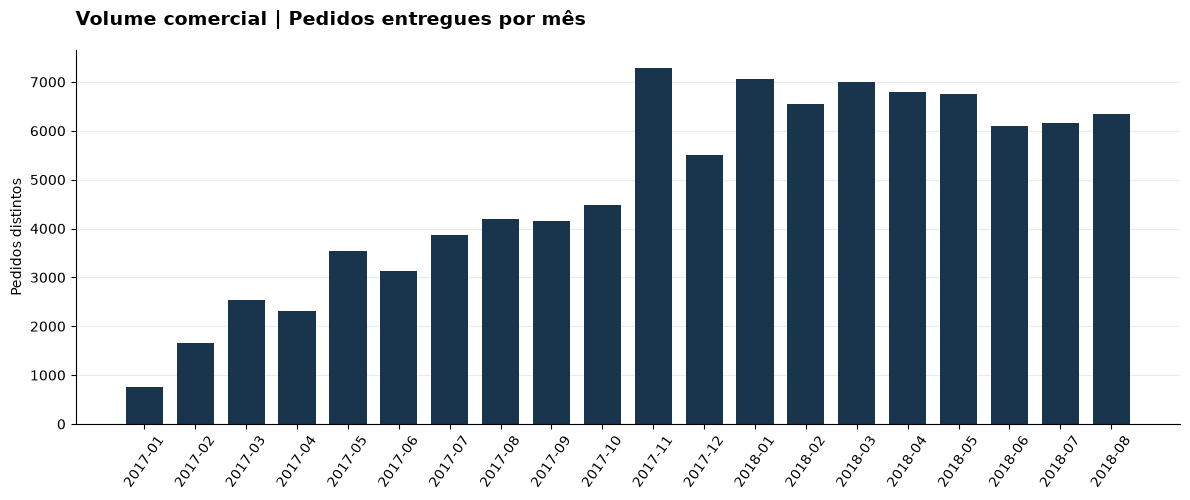

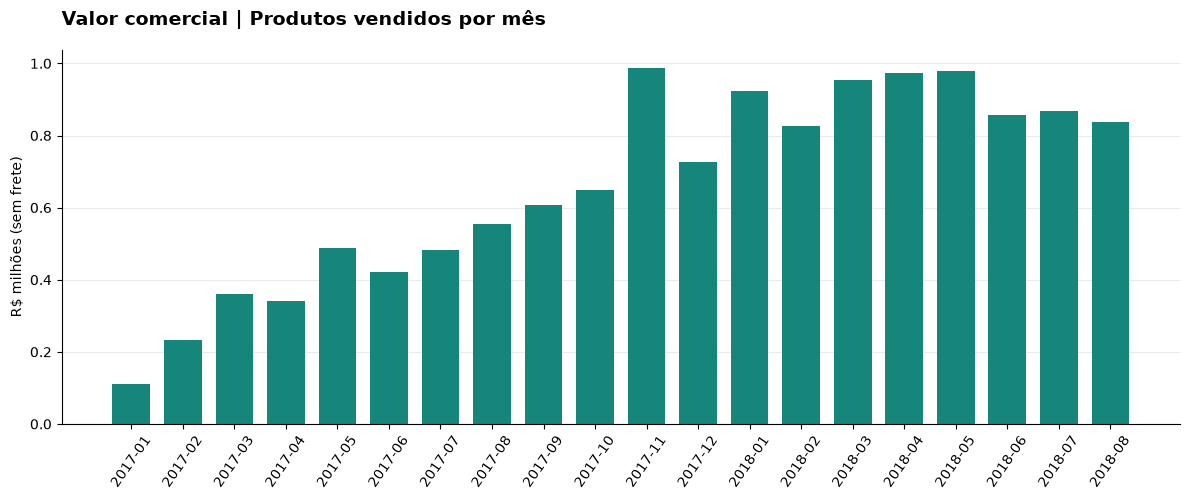

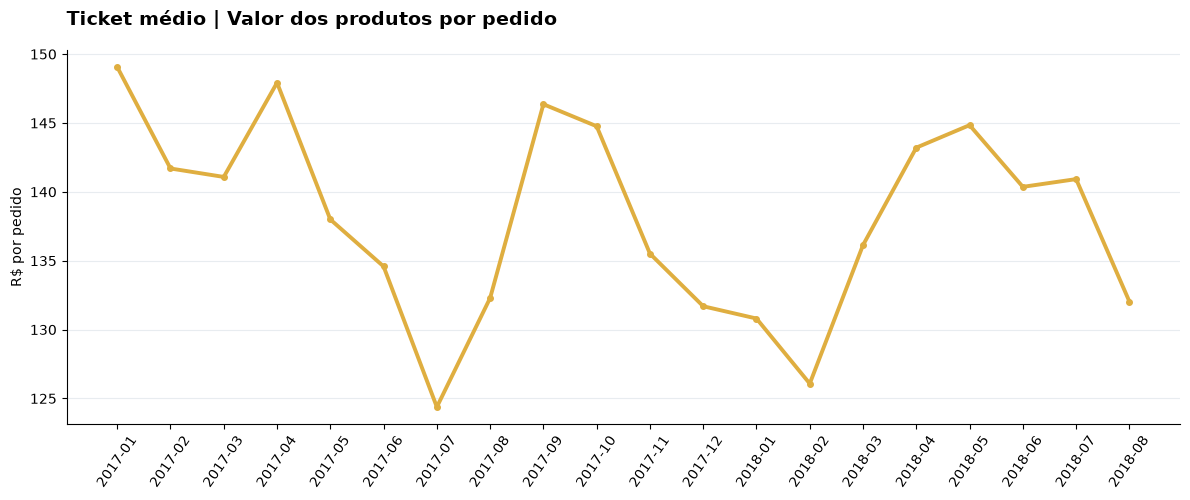

In [6]:
fig, ax = plt.subplots(figsize=(12, 5.1))
ax.bar(mensal["mes_str"], mensal["pedidos"], color=CORES["azul"], width=0.73)
ax.set_title("Volume comercial | Pedidos entregues por mês", loc="left", pad=18)
ax.set_ylabel("Pedidos distintos")
ax.grid(axis="y", color=CORES["grade"], alpha=.7); ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=55)
finalizar_grafico("01_pedidos_mensais.png")

fig, ax = plt.subplots(figsize=(12, 5.1))
ax.bar(mensal["mes_str"], mensal["valor_vendas"] / 1_000_000, color=CORES["turquesa"], width=.73)
ax.set_title("Valor comercial | Produtos vendidos por mês", loc="left", pad=18)
ax.set_ylabel("R$ milhões (sem frete)")
ax.grid(axis="y", color=CORES["grade"], alpha=.7); ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=55)
finalizar_grafico("02_valor_mensal.png")

fig, ax = plt.subplots(figsize=(12, 5.1))
ax.plot(mensal["mes_str"], mensal["ticket_medio"], color=CORES["dourado"], linewidth=2.8, marker="o", markersize=4)
ax.set_title("Ticket médio | Valor dos produtos por pedido", loc="left", pad=18)
ax.set_ylabel("R$ por pedido")
ax.grid(axis="y", color=CORES["grade"], alpha=.7); ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=55)
finalizar_grafico("03_ticket_medio_mensal.png")

## 7. Participação por categoria, UF e município

As participações são calculadas em relação ao **valor de vendas do período analisado**. Para evitar municípios homônimos de estados distintos, o agrupamento geográfico utiliza `cidade / UF`.

In [7]:
def tabela_participacao(coluna, rotulo):
    df = (vendas.groupby(coluna, dropna=False)
          .agg(valor_vendas=("valor_item", "sum"), pedidos=("order_id", "nunique"), unidades=("order_item_id", "size"))
          .reset_index().sort_values("valor_vendas", ascending=False))
    df["participacao_pct"] = 100 * df["valor_vendas"] / valor_total
    return df.rename(columns={coluna: rotulo})

categorias = tabela_participacao("categoria", "categoria")
ufs = tabela_participacao("uf", "uf")
municipios = tabela_participacao("cidade_uf", "municipio_uf")

print("Categorias com maior valor vendido:")
display(categorias.head(10).round(2))
print("Estados com maior valor vendido:")
display(ufs.head(10).round(2))
print("Municípios com maior valor vendido:")
display(municipios.head(10).round(2))
print("Participação das dez maiores categorias:", f"{categorias.head(10)['participacao_pct'].sum():.1f}%")

Categorias com maior valor vendido:


,categoria,valor_vendas,pedidos,unidades,participacao_pct
11,Beleza Saude,1229557.50,8610,9422,9.33
66,Relogios Presentes,1163465.91,5491,5855,8.83
13,Cama Mesa Banho,1022955.77,9267,10945,7.76
32,Esporte Lazer,952840.40,7513,8414,7.23
44,Informatica Acessorios,888055.59,6518,7632,6.74
54,Moveis Decoracao,706237.17,6258,8095,5.36
73,Utilidades Domesticas,614341.62,5734,6783,4.66
26,Cool Stuff,609158.00,3552,3711,4.62
8,Automotivo,577838.39,3802,4132,4.38
40,Ferramentas Jardim,469135.40,3443,4263,3.56


Estados com maior valor vendido:


,uf,valor_vendas,pedidos,unidades,participacao_pct
25,SP,5055587.13,40406,46338,38.36
18,RJ,1751433.85,12310,14097,13.29
10,MG,1548206.88,11319,12877,11.75
22,RS,726373.92,5328,6117,5.51
17,PR,664048.00,4903,5619,5.04
23,SC,504774.07,3537,4084,3.83
4,BA,493339.26,3253,3680,3.74
6,DF,295454.64,2074,2347,2.24
8,GO,281932.21,1950,2270,2.14
7,ES,267783.66,1992,2222,2.03


Municípios com maior valor vendido:


,municipio_uf,valor_vendas,pedidos,unidades,participacao_pct
3719,SAO PAULO / SP,1856066.93,15014,17364,14.08
3248,RIO DE JANEIRO / RJ,949362.77,6574,7559,7.20
463,BELO HORIZONTE / MG,344845.79,2687,3075,2.62
580,BRASILIA / DF,294770.95,2065,2333,2.24
1177,CURITIBA / PR,205581.65,1483,1715,1.56
730,CAMPINAS / SP,184206.29,1400,1616,1.40
3048,PORTO ALEGRE / RS,182183.16,1340,1571,1.38
3341,SALVADOR / BA,173273.05,1188,1358,1.31
1574,GUARULHOS / SP,138928.29,1143,1293,1.05
2529,NITEROI / RJ,115590.36,824,957,0.88


Participação das dez maiores categorias: 62.5%


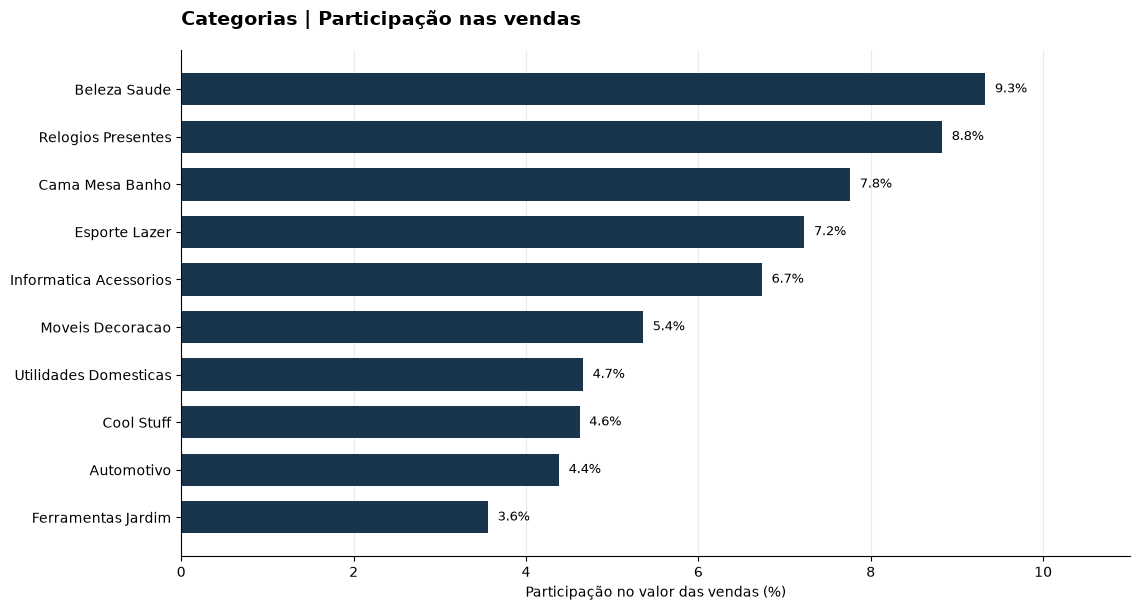

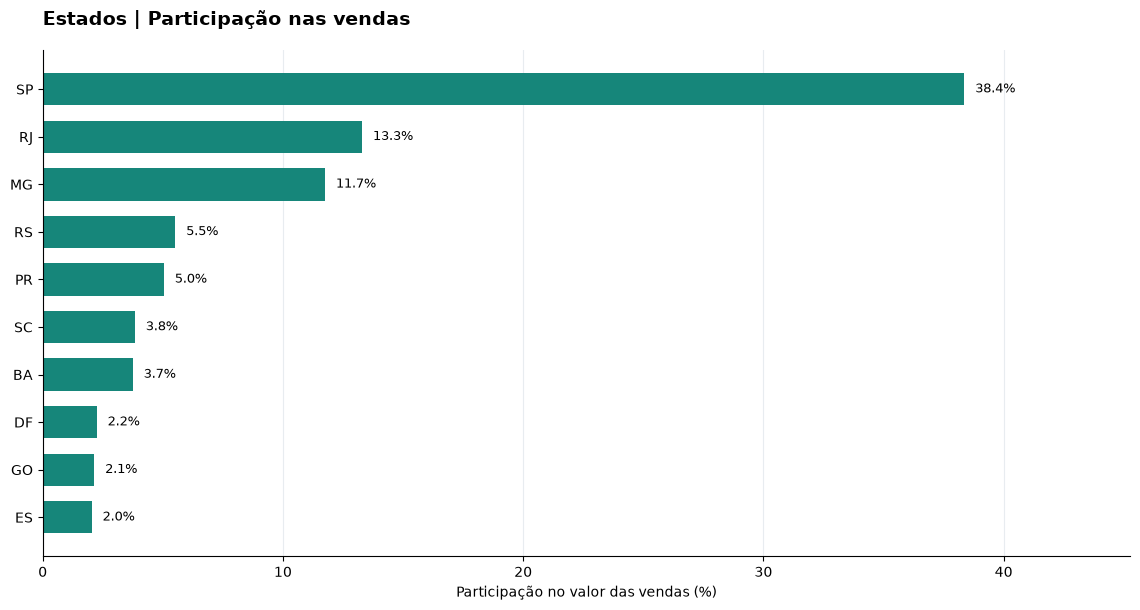

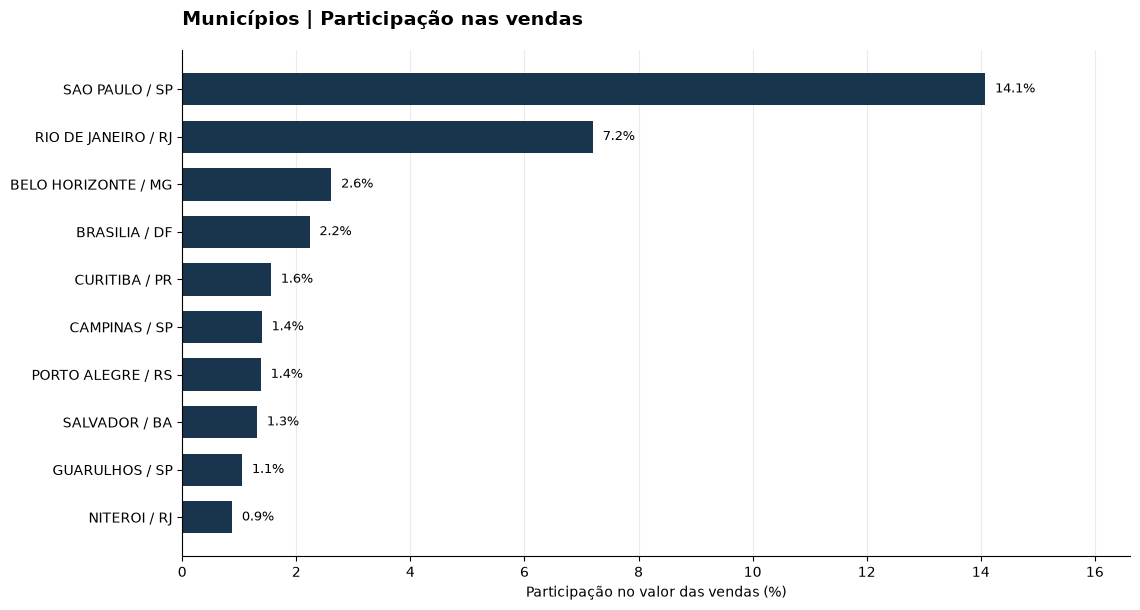

In [8]:
def grafico_ranking(tabela, coluna, titulo, arquivo, cor, top=10):
    dados = tabela.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(11.5, max(5.0, .48 * len(dados) + 1.4)))
    ax.barh(dados[coluna], dados["participacao_pct"], color=cor, height=.68)
    ax.set_title(titulo, loc="left", pad=18)
    ax.set_xlabel("Participação no valor das vendas (%)")
    ax.grid(axis="x", color=CORES["grade"], alpha=.7)
    ax.set_axisbelow(True)
    ax.set_xlim(0, max(1, dados["participacao_pct"].max()) * 1.18)
    for i, v in enumerate(dados["participacao_pct"]):
        ax.text(v + dados["participacao_pct"].max()*.012, i, f"{v:.1f}%", va="center", fontsize=9)
    finalizar_grafico(arquivo)

grafico_ranking(categorias, "categoria", "Categorias | Participação nas vendas", "04_categorias.png", CORES["azul"])
grafico_ranking(ufs, "uf", "Estados | Participação nas vendas", "05_estados.png", CORES["turquesa"])
grafico_ranking(municipios, "municipio_uf", "Municípios | Participação nas vendas", "06_municipios.png", CORES["azul"])

## 8. Produtos mais vendidos × produtos de maior receita

São dois rankings diferentes:

- **Mais vendidos:** quantidade de unidades comercializadas;
- **Maior receita de produtos:** soma do preço dos itens.

Um produto pode liderar em unidades vendidas e não liderar em valor comercializado.

> A Olist pública identifica produtos por `product_id`, mas não traz nome comercial. O gráfico mostra categoria e os primeiros caracteres do código; a tabela exportada conserva o código completo.

In [9]:
rank_produtos = (vendas.groupby("product_id", dropna=False)
                 .agg(unidades=("order_item_id", "size"),
                      pedidos=("order_id", "nunique"),
                      valor_vendas=("valor_item", "sum"),
                      categoria=("categoria", "first"))
                 .reset_index())
rank_produtos["preco_medio_item"] = rank_produtos["valor_vendas"] / rank_produtos["unidades"]
rank_produtos["rotulo"] = rank_produtos["categoria"].str.slice(0, 20) + " · " + rank_produtos["product_id"].astype(str).str.slice(0, 8)

produtos_unidades = rank_produtos.sort_values(["unidades", "valor_vendas"], ascending=False).reset_index(drop=True)
produtos_valor = rank_produtos.sort_values(["valor_vendas", "unidades"], ascending=False).reset_index(drop=True)

print("Top 10 produtos por unidades:")
display(produtos_unidades[["product_id", "categoria", "unidades", "pedidos", "valor_vendas"]].head(10).round(2))
print("Top 10 produtos por valor comercial:")
display(produtos_valor[["product_id", "categoria", "unidades", "pedidos", "valor_vendas"]].head(10).round(2))

Top 10 produtos por unidades:


,product_id,categoria,unidades,pedidos,valor_vendas
0,aca2eb7d00ea1a7b8ebd4e68314663af,Moveis Decoracao,520,425,37104.30
1,422879e10f46682990de24d770e7f83d,Ferramentas Jardim,484,352,26577.22
2,99a4788cb24856965c36a24e339b6058,Cama Mesa Banho,477,456,42049.66
3,389d119b48cf3043d311335e499d9c6b,Ferramentas Jardim,390,309,21336.79
4,368c6c730842d78016ad823897a372db,Ferramentas Jardim,388,291,21056.80
5,53759a2ecddad2bb87a079a1f1519f73,Ferramentas Jardim,373,287,20387.20
6,d1c427060a0f73f6b889a5c7c61f2ac4,Informatica Acessorios,332,313,45620.56
7,53b36df67ebb7c41585e8d54d6772e08,Relogios Presentes,321,304,37454.63
8,154e7e31ebfa092203795c972e5804a6,Beleza Saude,274,262,6173.26
9,3dd2a17168ec895c781a9191c1e95ad7,Informatica Acessorios,272,253,40782.80


Top 10 produtos por valor comercial:


,product_id,categoria,unidades,pedidos,valor_vendas
0,bb50f2e236e5eea0100680137654686c,Beleza Saude,194,186,63560.00
1,6cdd53843498f92890544667809f1595,Beleza Saude,153,148,53652.30
2,d6160fb7873f184099d9bc95e30376af,Pcs,33,33,45949.35
3,d1c427060a0f73f6b889a5c7c61f2ac4,Informatica Acessorios,332,313,45620.56
4,99a4788cb24856965c36a24e339b6058,Cama Mesa Banho,477,456,42049.66
5,3dd2a17168ec895c781a9191c1e95ad7,Informatica Acessorios,272,253,40782.80
6,25c38557cf793876c5abdd5931f922db,Bebes,38,38,38907.32
7,5f504b3a1c75b73d6151be81eb05bdc9,Cool Stuff,63,63,37733.90
8,53b36df67ebb7c41585e8d54d6772e08,Relogios Presentes,321,304,37454.63
9,aca2eb7d00ea1a7b8ebd4e68314663af,Moveis Decoracao,520,425,37104.30


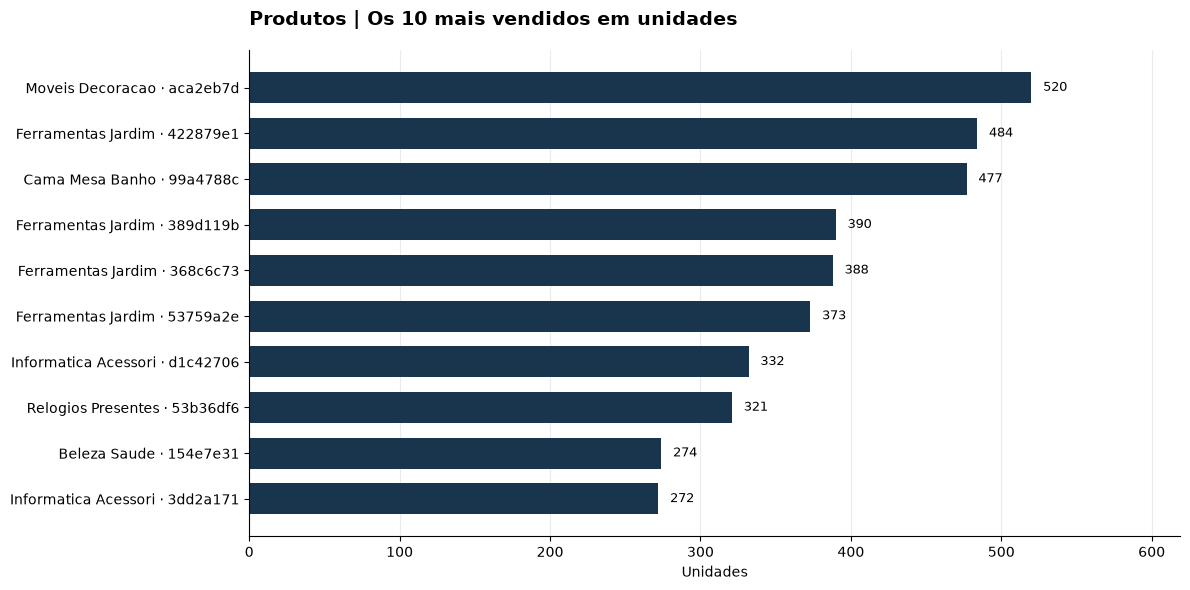

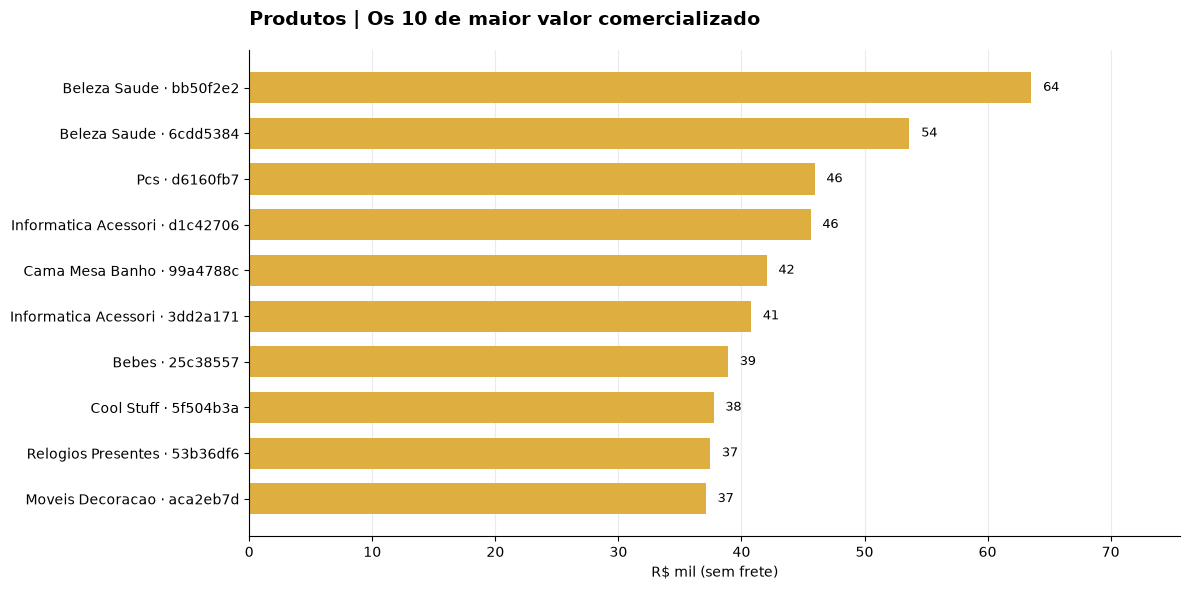

In [10]:
def grafico_produtos(tabela, coluna_valor, titulo, eixo, arquivo, cor):
    dados = tabela.head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(12, 6))
    valores = dados[coluna_valor].to_numpy() / (1000 if coluna_valor == "valor_vendas" else 1)
    ax.barh(dados["rotulo"], valores, color=cor, height=.68)
    ax.set_title(titulo, loc="left", pad=18)
    ax.set_xlabel(eixo)
    ax.grid(axis="x", color=CORES["grade"], alpha=.7); ax.set_axisbelow(True)
    ax.set_xlim(0, max(valores) * 1.19)
    for i, val in enumerate(valores):
        ax.text(val + max(valores)*.015, i, f"{val:,.0f}".replace(",", "."), va="center", fontsize=9)
    finalizar_grafico(arquivo)

grafico_produtos(produtos_unidades, "unidades", "Produtos | Os 10 mais vendidos em unidades", "Unidades", "07_produtos_unidades.png", CORES["azul"])
grafico_produtos(produtos_valor, "valor_vendas", "Produtos | Os 10 de maior valor comercializado", "R$ mil (sem frete)", "08_produtos_receita.png", CORES["dourado"])

## 9. Leitura gerencial e recomendações

As recomendações abaixo são **pontos de investigação comercial**, não afirmações sobre lucratividade. O conjunto Olist não possui custos, margens, orçamento de marketing nem receitas de comissão da plataforma.

In [11]:
maior_mes = mensal.loc[mensal["valor_vendas"].idxmax()]
mes_lider = maior_mes["mes_str"]
categoria_lider = categorias.iloc[0]
uf_lider = ufs.iloc[0]
cidade_lider = municipios.iloc[0]
produto_qtd = produtos_unidades.iloc[0]
produto_valor = produtos_valor.iloc[0]

resumo = f"""# Resumo comercial | Olist — Vendas e Receita

**Período:** {INICIO:%m/%Y} a {(FIM_EXCLUSIVO - pd.Timedelta(days=1)):%m/%Y}.

## Principais resultados

- Pedidos entregues com itens: **{numero(qtd_pedidos)}**.
- Unidades comercializadas: **{numero(len(vendas))}**.
- Valor das vendas de produtos, sem frete: **{moeda(valor_total,2)}**.
- Ticket médio por pedido: **{moeda(ticket,2)}**.
- Mês com maior valor vendido: **{mes_lider}** ({moeda(maior_mes['valor_vendas'],2)}).
- Categoria líder: **{categoria_lider['categoria']}**, com **{categoria_lider['participacao_pct']:.1f}%** do valor vendido.
- UF líder: **{uf_lider['uf']}**, com **{uf_lider['participacao_pct']:.1f}%**.
- Município líder: **{cidade_lider['municipio_uf']}**, com **{cidade_lider['participacao_pct']:.1f}%**.
- Produto com mais unidades: **{produto_qtd['product_id']}**, categoria {produto_qtd['categoria']}, com {numero(produto_qtd['unidades'])} unidades.
- Produto com maior valor vendido: **{produto_valor['product_id']}**, categoria {produto_valor['categoria']}, com {moeda(produto_valor['valor_vendas'],2)}.

## Recomendações para investigação

1. Verificar as causas dos meses de maior e menor volume de pedidos, antes de planejar campanhas sazonais.
2. Avaliar estoque e disponibilidade das categorias e produtos líderes; confrontar faturamento com margem antes de priorizar orçamento.
3. Observar a concentração das vendas por UF e município ao escolher onde testar novas ações comerciais.
4. Separar sempre o ranking de produtos por **unidades** do ranking por **valor**: ambos respondem a decisões diferentes.

## Limitações

- O valor analisado é a soma dos preços de itens em pedidos entregues; **exclui frete** e não representa receita contábil nem lucro da Olist.
- Não foram estimadas conversão, margem, custo de aquisição, demanda reprimida ou retorno sobre investimento.
- A base é pública e histórica. O período foi definido para evitar fronteiras incompletas; não indica situação atual.
- Produtos são identificados por código, pois não há nomes comerciais disponíveis.
"""

display(Markdown(resumo))

# Resumo comercial | Olist — Vendas e Receita

**Período:** 01/2017 a 08/2018.

## Principais resultados

- Pedidos entregues com itens: **96.211**.
- Unidades comercializadas: **109.880**.
- Valor das vendas de produtos, sem frete: **R$ 13.181.027,13**.
- Ticket médio por pedido: **R$ 137,00**.
- Mês com maior valor vendido: **2017-11** (R$ 987.765,37).
- Categoria líder: **Beleza Saude**, com **9.3%** do valor vendido.
- UF líder: **SP**, com **38.4%**.
- Município líder: **SAO PAULO / SP**, com **14.1%**.
- Produto com mais unidades: **aca2eb7d00ea1a7b8ebd4e68314663af**, categoria Moveis Decoracao, com 520 unidades.
- Produto com maior valor vendido: **bb50f2e236e5eea0100680137654686c**, categoria Beleza Saude, com R$ 63.560,00.

## Recomendações para investigação

1. Verificar as causas dos meses de maior e menor volume de pedidos, antes de planejar campanhas sazonais.
2. Avaliar estoque e disponibilidade das categorias e produtos líderes; confrontar faturamento com margem antes de priorizar orçamento.
3. Observar a concentração das vendas por UF e município ao escolher onde testar novas ações comerciais.
4. Separar sempre o ranking de produtos por **unidades** do ranking por **valor**: ambos respondem a decisões diferentes.

## Limitações

- O valor analisado é a soma dos preços de itens em pedidos entregues; **exclui frete** e não representa receita contábil nem lucro da Olist.
- Não foram estimadas conversão, margem, custo de aquisição, demanda reprimida ou retorno sobre investimento.
- A base é pública e histórica. O período foi definido para evitar fronteiras incompletas; não indica situação atual.
- Produtos são identificados por código, pois não há nomes comerciais disponíveis.


### Conferência dos resultados

Antes de exportar, confirmamos que os totais das tabelas de meses, categorias, estados, municípios e produtos correspondem ao total de vendas calculado.

In [12]:
assert int(mensal["pedidos"].sum()) >= qtd_pedidos  # um pedido só pertence a um mês; igualdade esperada na base Olist
assert int(mensal["pedidos"].sum()) == qtd_pedidos, "Pedidos não conciliam por mês."
for nome, total in {
    "Meses": mensal["valor_vendas"].sum(),
    "Categorias": categorias["valor_vendas"].sum(),
    "UFs": ufs["valor_vendas"].sum(),
    "Municípios": municipios["valor_vendas"].sum(),
    "Produtos": rank_produtos["valor_vendas"].sum(),
}.items():
    assert np.isclose(total, valor_total, rtol=1e-9, atol=0.01), f"Valor não concilia em {nome}"
print("Conferência aprovada: todos os valores das tabelas conciliam com a base comercial.")

Conferência aprovada: todos os valores das tabelas conciliam com a base comercial.


## 10. Exportação dos resultados

Os resultados serão salvos em `outputs/tabelas/` como arquivos CSV e em `outputs/graficos/` como PNG. Esses arquivos podem ser utilizados depois no Power BI, Word ou PowerPoint.

In [13]:
TABELAS = SAIDA / "tabelas"
TABELAS.mkdir(parents=True, exist_ok=True)

exportacoes = {
    "diagnostico_bases.csv": diagnostico,
    "status_pedidos.csv": status_pedidos,
    "evolucao_mensal.csv": mensal.drop(columns=["mes"]),
    "participacao_categorias.csv": categorias,
    "participacao_uf.csv": ufs,
    "participacao_municipios.csv": municipios,
    "produtos_mais_vendidos.csv": produtos_unidades,
    "produtos_maior_receita.csv": produtos_valor,
}
for nome, tabela in exportacoes.items():
    tabela.to_csv(TABELAS / nome, index=False, sep=";", decimal=",", encoding="utf-8-sig")

(SAIDA / "resumo_comercial.md").write_text(resumo, encoding="utf-8")
print(f"Exportados: {len(exportacoes)} CSVs, 8 gráficos PNG e 1 resumo Markdown")
print("Local dos resultados:", SAIDA)

Exportados: 8 CSVs, 8 gráficos PNG e 1 resumo Markdown
Local dos resultados: c:\Users\F6363856\OneDrive - Banco do Brasil S.A\Área de Trabalho\Pós Data Analytics\Fase 1\olist-vendas-e-receita\outputs
